## Лабораторная № 3
#### Часть 1. Работа с наборами данных (Обязательное условие)
Подбор датасетов: Для выполнения работы используются два типа задач регрессии:
* Датасет №1 (Парная регрессия): Набор данных с одной независимой переменной (например, классические датасеты простой линейной регрессии, такие как зависимость стоимости недвижимости от площади или уровня инфляции от безработицы).
* Датасет №2 (Множественная регрессия): Набор данных с несколькими независимыми переменными (рекомендуется использовать архивный датасет затрат на рекламу и объемов продаж — Advertising Dataset).

Требование к смене данных: Выбранные наборы данных должны полностью отличаться от тех, которые вы исследовали в лабораторных работах №1 и №2.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## Часть 2. Модель парной линейной регрессии (Один признак)

В качестве первого набора данных используется датасет зависимости уровня заработной платы от опыта работы (`Salary_Data.csv`).

* **Независимая переменная ($X$):** `YearsExperience` (Опыт работы в годах)
* **Зависимая переменная ($y$):** `Salary` (Заработная плата)

In [11]:
print("Скачивание датасета (Парная регрессия)")
path_simple = kagglehub.dataset_download("karthickveerakumar/salary-data-simple-linear-regression")

csv_file_simple = [f for f in os.listdir(path_simple) if f.endswith('.csv')][0]
df_simple = pd.read_csv(os.path.join(path_simple, csv_file_simple))

print("\nПервые 5 строк датасета")
display(df_simple.head())

print("\nИнформация о типах и пропусках")
df_simple.info()

Скачивание датасета (Парная регрессия)

Первые 5 строк датасета


,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0



Информация о типах и пропусках
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 676.0 bytes


### Разделение выборки и обучение модели парной регрессии

Выделяем целевую переменную $y$ и независимый признак $X$. Разделяем выборку на обучающую ($80\%$) и тестовую ($20\%$) с фиксированным `random_state=42`, после чего обучаем модель `LinearRegression`.

In [12]:
X_simple = df_simple[['YearsExperience']]
y_simple = df_simple['Salary']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simple, y_simple, test_size=0.2, random_state=42)

model_simple = LinearRegression()
model_simple.fit(X_train_s, y_train_s)

slope = model_simple.coef_[0]
intercept = model_simple.intercept_

print(f"Параметры обученной модели:")
print(f"Уравнение регрессии: y = {intercept:.2f} + {slope:.2f} * X")

Параметры обученной модели:
Уравнение регрессии: y = 25321.58 + 9423.82 * X


### Визуализация результатов парной регрессии
Построим график, отображающий фактические данные обучающей и тестовой выборок, а также полученную прямую.

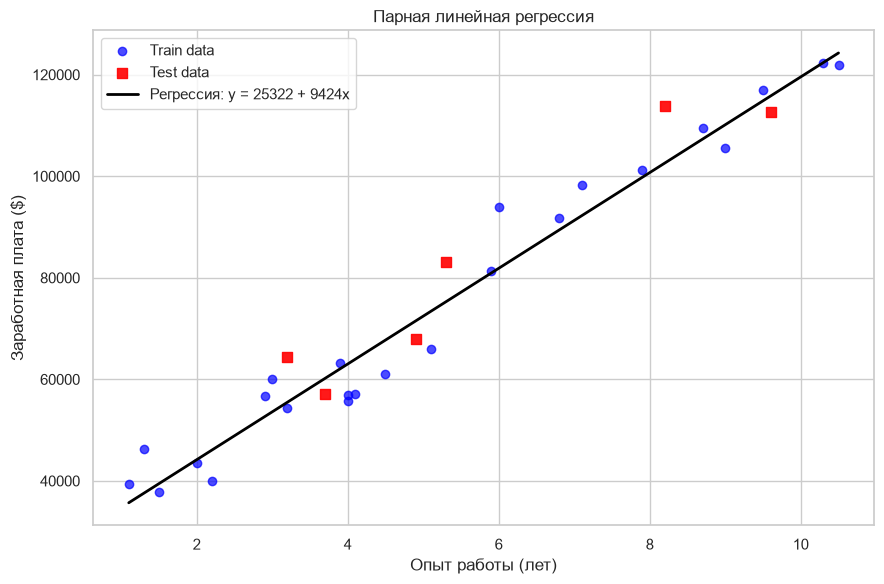

In [13]:
plt.figure(figsize=(9, 6))

plt.scatter(X_train_s, y_train_s, color='blue', alpha=0.7, label='Train data')
plt.scatter(X_test_s, y_test_s, color='red', alpha=0.9, marker='s', s=60, label='Test data')

X_range = np.linspace(X_simple.min(), X_simple.max(), 100).reshape(-1, 1)
y_range_pred = model_simple.predict(pd.DataFrame(X_range, columns=['YearsExperience']))
plt.plot(X_range, y_range_pred, color='black', linewidth=2, label=f'Регрессия: y = {intercept:.0f} + {slope:.0f}x')

plt.xlabel('Опыт работы (лет)')
plt.ylabel('Заработная плата ($)')
plt.title('Парная линейная регрессия')
plt.legend()
plt.tight_layout()
plt.show()

## Часть 3. Модель множественной линейной регрессии и эксперименты с признаками

Используем классический датасет `Advertising Dataset` напрямую с Kaggle.

* **Признаки ($X$):** `TV`, `Radio`, `Newspaper` (бюджеты на рекламу)
* **Целевая переменная ($y$):** `Sales` (объем продаж)

In [14]:
print("Скачивание датасета (Множественная регрессия)")
path_multi = kagglehub.dataset_download("ashydv/advertising-dataset")

csv_file_multi = [f for f in os.listdir(path_multi) if f.endswith('.csv')][0]
df_multi = pd.read_csv(os.path.join(path_multi, csv_file_multi))

if 'Unnamed: 0' in df_multi.columns:
    df_multi = df_multi.drop(columns=['Unnamed: 0'])

print("\nПервые 5 строк датасета")
display(df_multi.head())

print("\nИнформация о типах и пропусках")
df_multi.info()

Скачивание датасета (Множественная регрессия)

Первые 5 строк датасета


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9



Информация о типах и пропусках
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


### Проведение серии вычислительных экспериментов

Сформируем три комбинации входных фичей для оценки их влияния на точность предсказания:
1. **Эксперимент А:** Обучение только на одном признаке (`TV`).
2. **Эксперимент Б:** Обучение на комбинации двух признаков (`TV` + `Radio`).
3. **Эксперимент В:** Обучение на полном наборе признаков (`TV` + `Radio` + `Newspaper`).

In [15]:
y_multi = df_multi['Sales']

experiments = {
    'Эксперимент А (TV)': ['TV'],
    'Эксперимент Б (TV + Radio)': ['TV', 'Radio'],
    'Эксперимент В (TV + Radio + Newspaper)': ['TV', 'Radio', 'Newspaper']
}

models_multi = {}
test_data_multi = {}

for exp_name, features in experiments.items():
    X_exp = df_multi[features]
    
    X_train, X_test, y_train, y_test = train_test_split(
        X_exp, y_multi, test_size=0.2, random_state=42
    )
    
    model = LinearRegression()
    model.fit(X_train, y_train)
    
    models_multi[exp_name] = model
    test_data_multi[exp_name] = (X_test, y_test)
    
    print(f"{exp_name}")
    print(f"Intercept (w0): {model.intercept_:.4f}")
    for feat, coef in zip(features, model.coef_):
        print(f"Коэффициент {feat} (w): {coef:.4f}")
    print()

Эксперимент А (TV)
Intercept (w0): 7.0071
Коэффициент TV (w): 0.0555

Эксперимент Б (TV + Radio)
Intercept (w0): 4.7914
Коэффициент TV (w): 0.0545
Коэффициент Radio (w): 0.1033

Эксперимент В (TV + Radio + Newspaper)
Intercept (w0): 4.7141
Коэффициент TV (w): 0.0545
Коэффициент Radio (w): 0.1009
Коэффициент Newspaper (w): 0.0043



## Часть 3. Оценка качества и сравнение моделей

Сведём метрики всех экспериментов (MAE, MSE, $R^2$) в единую таблицу для анализа.

In [16]:
results = []

y_pred_s = model_simple.predict(X_test_s)
results.append({
    'Модель / Эксперимент': 'Парная регрессия (Salary)',
    'Признаки': 'YearsExperience',
    'MAE': mean_absolute_error(y_test_s, y_pred_s),
    'MSE': mean_squared_error(y_test_s, y_pred_s),
    'R2-Score': r2_score(y_test_s, y_pred_s)
})

for exp_name, model in models_multi.items():
    X_test, y_test = test_data_multi[exp_name]
    y_pred = model.predict(X_test)
    
    results.append({
        'Модель / Эксперимент': exp_name,
        'Признаки': ', '.join(experiments[exp_name]),
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred),
        'R2-Score': r2_score(y_test, y_pred)
    })

df_metrics = pd.DataFrame(results)
print("Сравнительная таблица метрик качества")
display(df_metrics.round(4))

Сравнительная таблица метрик качества


,Модель / Эксперимент,Признаки,MAE,MSE,R2-Score
0,Парная регрессия (Salary),YearsExperience,6286.4538,4.983010e+07,0.9024
1,Эксперимент А (TV),TV,1.9503,6.101100e+00,0.8026
2,Эксперимент Б (TV + Radio),"TV, Radio",1.2670,2.846600e+00,0.9079
3,Эксперимент В (TV + Radio + Newspaper),"TV, Radio, Newspaper",1.2748,2.907800e+00,0.9059


### Аналитический вывод по результатам экспериментов

Опираясь на полученную сравнительную таблицу метрик качества:

1. **Парная регрессия (Salary):** Модель показала высокий коэффициент детерминации ($R^2 = 0.9024$). Это подтверждает, что стаж работы (`YearsExperience`) имеет сильную линейную зависимость с заработной платой и объясняет более 90% её дисперсии.
2. **Множественная регрессия и отбор признаков (Advertising):**
   * **Эксперимент А (только TV):** Использование только одного признака дает базовый результат: $R^2 = 0.8026$ при средней абсолютной ошибке (MAE) $1.9503$.
   * **Эксперимент Б (TV + Radio):** Добавление бюджета на радио рекламу существенно улучшает предсказательную способность модели. Коэффициент детерминации $R^2$ возрастает до $0.9079$, а ошибки заметно падают (MAE снижается до $1.2670$, MSE — с $6.1011$ до $2.8466$).
   * **Эксперимент В (TV + Radio + Newspaper):** Включение в модель затрат на рекламу в газетах (`Newspaper`) оказалось нецелесообразным. Качество модели не улучшилось, а наоборот, слегка упало: $R^2$ снизился до $0.9059$, а MAE немного возросла до $1.2748$.
3. **Итог:** Наилучшей (оптимальной) моделью для предсказания продаж является конфигурация **Эксперимента Б (TV + Radio)**. Признак `Newspaper` оказался избыточным (шумовым), так как он не несет полезной информации для целевой переменной.

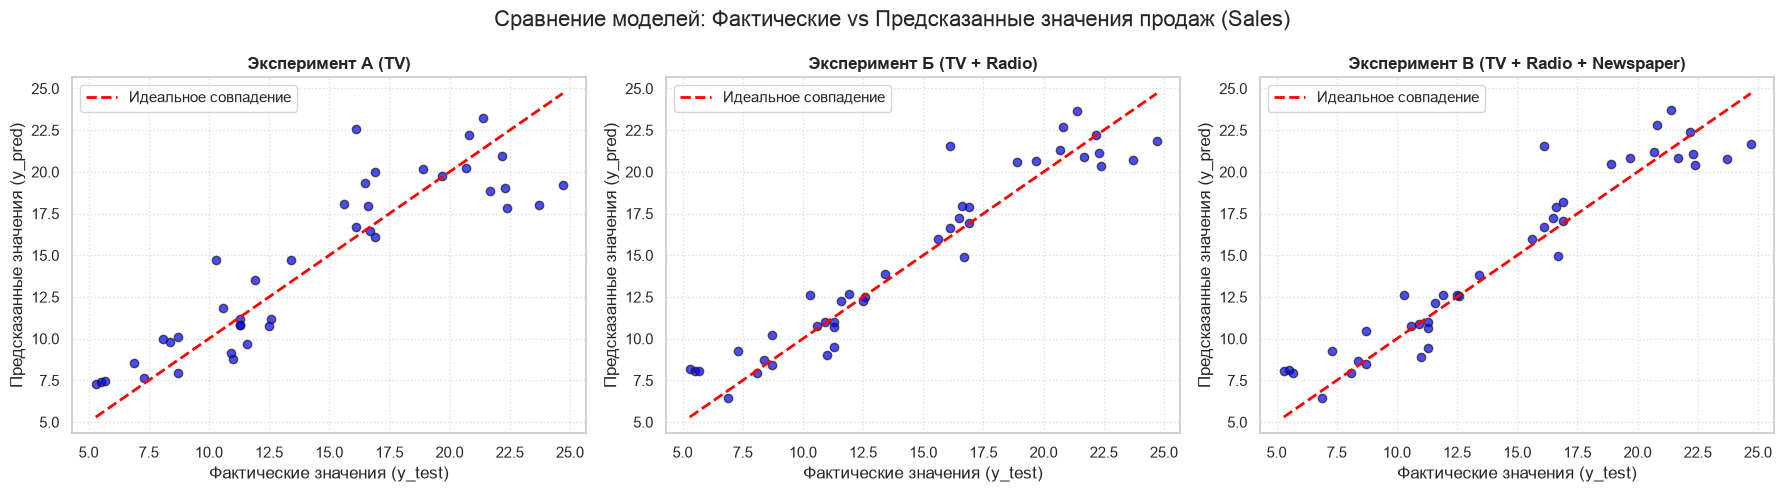

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Сравнение моделей: Фактические vs Предсказанные значения продаж (Sales)', fontsize=16)

for ax, (exp_name, model) in zip(axes, models_multi.items()):
    X_test, y_test = test_data_multi[exp_name]
    y_pred = model.predict(X_test)
    
    ax.scatter(y_test, y_pred, alpha=0.7, color='blue', edgecolor='k')
    
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Идеальное совпадение')
    
    ax.set_title(exp_name, fontsize=12, fontweight='bold')
    ax.set_xlabel('Фактические значения (y_test)')
    ax.set_ylabel('Предсказанные значения (y_pred)')
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Часть 4. Экспорт и сохранение обученных моделей

В ходе выполнения лабораторной работы были обучены 4 различные модели линейной регрессии:
1. Модель парной регрессии (Опыт $\rightarrow$ Зарплата)
2. Модель множественной регрессии А (TV $\rightarrow$ Продажи)
3. Модель множественной регрессии Б (TV, Radio $\rightarrow$ Продажи)
4. Модель множественной регрессии В (TV, Radio, Newspaper $\rightarrow$ Продажи)

Сохраним их в файлы формата `.pkl` (pickle) с помощью библиотеки `joblib` для возможности дальнейшего использования (деплоя) без необходимости переобучения.

In [18]:
os.makedirs('saved_models', exist_ok=True)

joblib.dump(model_simple, 'saved_models/model_1_simple_salary.pkl')
print("Модель 1 (Парная) сохранена.")

joblib.dump(models_multi['Эксперимент А (TV)'], 'saved_models/model_2_multi_A.pkl')
print("Модель 2 (Эксперимент А) сохранена.")

joblib.dump(models_multi['Эксперимент Б (TV + Radio)'], 'saved_models/model_3_multi_B.pkl')
print("Модель 3 (Эксперимент Б) сохранена.")

joblib.dump(models_multi['Эксперимент В (TV + Radio + Newspaper)'], 'saved_models/model_4_multi_C.pkl')
print("Модель 4 (Эксперимент В) сохранена.")

print("\nВсе 4 модели успешно экспортированы в папку 'saved_models'!")

Модель 1 (Парная) сохранена.
Модель 2 (Эксперимент А) сохранена.
Модель 3 (Эксперимент Б) сохранена.
Модель 4 (Эксперимент В) сохранена.

Все 4 модели успешно экспортированы в папку 'saved_models'!
